# Multi-model precipitation-type verification against mPING

End-to-end verification for:

- Aurora — EDNN
- Aurora — Bourgouin
- GraphCast — EDNN
- GraphCast — Bourgouin
- Pangu-Weather — EDNN
- Pangu-Weather — Bourgouin
- GFS — native GFS precipitation type
- GFS — EDNN

The workflow uses the same mPING QC and forecast-day design for all systems, then builds a **common-valid sample** for direct comparison.

## Main analyses

1. **Forecast skill:** CSI heatmaps as the primary summary; POD, FAR and frequency bias retained in tables/secondary heatmaps.
2. **Rain/snow reassignment:** for mPING-observed Ice Pellet and Freezing Rain, quantify the fraction subsequently diagnosed as Rain or Snow.
3. **EDNN uncertainty:** total predictive uncertainty (`aleatoric + epistemic`) for Aurora, GraphCast, Pangu-Weather and GFS, conditioned on the mPING-observed class. Epistemic and aleatoric components are retained for diagnosis.
4. **Attribution-oriented comparisons:** EDNN vs Bourgouin within the same AI-NWP and native GFS vs GFS-EDNN.

The +0 h initialization state is excluded. Day 1 uses +6/+12/+18/+24 h; Day 7 uses +150/+156/+162/+168 h.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

# ============================================================
# PATHS
# ============================================================

MPING_PATH = "/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/mPING_hourafter_interpolated_QC3.parquet"

AI_BASE = Path("/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE")
MODEL_DIRS = {
    "Aurora": AI_BASE / "au_ptype",
    "GraphCast": AI_BASE / "gc_ptype",
    "Pangu-Weather": AI_BASE / "pw_ptype",
    "GFS": Path("/glade/derecho/scratch/sakor/gfs/processed"),
}

OUT = AI_BASE / "verification_multimodel"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

# ============================================================
# EXPERIMENT
# ============================================================

START = pd.Timestamp("2021-12-01 00:00:00")
END = pd.Timestamp("2022-04-01 00:00:00")  # exclusive
CONSENSUS = 70.0

LAT_MIN, LAT_MAX = 24.0, 50.0
LON_MIN, LON_MAX = -125.0, -66.0
MAX_DIST_KM = 30.0

PTYPE_COLS = {
    "sn_percent": "Snow",
    "ra_percent": "Rain",
    "pl_percent": "Ice Pellet",
    "fzra_percent": "Freezing Rain",
}

CLASS_NAMES = {0: "Rain", 1: "Snow", 2: "Ice Pellet", 3: "Freezing Rain"}
CLASS_CODES = {v: k for k, v in CLASS_NAMES.items()}
CLASS_ORDER = ["Rain", "Snow", "Ice Pellet", "Freezing Rain"]
FRZR_IP_CLASSES = ["Ice Pellet", "Freezing Rain"]

EPI_VARS = {
    "Rain": "ML_rain_epi", "Snow": "ML_snow_epi",
    "Ice Pellet": "ML_icep_epi", "Freezing Rain": "ML_frzr_epi",
}
ALE_VARS = {
    "Rain": "ML_rain_ale", "Snow": "ML_snow_ale",
    "Ice Pellet": "ML_icep_ale", "Freezing Rain": "ML_frzr_ale",
}

EXTRACT_VARS = [
    "ML_ptype",
    "ML_rain_ale", "ML_snow_ale", "ML_icep_ale", "ML_frzr_ale",
    "ML_rain_epi", "ML_snow_epi", "ML_icep_epi", "ML_frzr_epi",
    "BOURG_ptype", "GFS_ptype",
]


## 1. mPING QC and common Day 1–7 verification index


In [2]:
def prepare_mping(path):
    cols = ["datetime","lat","lon","report_count","sn_percent","ra_percent","pl_percent","fzra_percent"]
    d = pd.read_parquet(path, columns=cols)
    d["datetime"] = pd.to_datetime(d["datetime"])

    d = d[(d.datetime >= START) & (d.datetime < END)].copy()
    d = d[d.datetime.dt.hour.isin([0,6,12,18])].copy()
    d = d[d.lat.between(LAT_MIN,LAT_MAX) & d.lon.between(LON_MIN,LON_MAX)].copy()

    pcols = list(PTYPE_COLS)
    d["obs_class"] = d[pcols].idxmax(axis=1).map(PTYPE_COLS)
    d["obs_consensus"] = d[pcols].max(axis=1)
    if d.obs_consensus.max() <= 1:
        d["obs_consensus"] *= 100

    d = d[d.obs_consensus >= CONSENSUS].reset_index(drop=True)
    d["obs_id"] = np.arange(len(d), dtype=np.int64)
    return d[["obs_id","datetime","lat","lon","report_count","obs_class","obs_consensus"]]

def expand_forecast_days(obs):
    out = []
    for day in range(1,8):
        x = obs.copy()
        h = x.datetime.dt.hour
        x["forecast_day"] = day
        x["lead_hour"] = np.where(h == 0, 24*day, h + 24*(day-1)).astype(np.int16)
        x["init_time"] = x.datetime - pd.to_timedelta(x.lead_hour, unit="h")
        out.append(x)
    return pd.concat(out, ignore_index=True)

obs = prepare_mping(MPING_PATH)
master = expand_forecast_days(obs)

assert master.groupby("obs_id").size().eq(7).all()
assert not (master.lead_hour == 0).any()

print(f"mPING observations after >=70% QC: {len(obs):,}")
print(f"Expanded verification rows: {len(master):,}")
print("\nLead hours by forecast day:")
print(master.groupby("forecast_day").lead_hour.apply(lambda x: sorted(x.unique())))
print("\nObserved classes:")
print(obs.obs_class.value_counts().reindex(CLASS_ORDER))


mPING observations after >=70% QC: 29,834
Expanded verification rows: 208,838

Lead hours by forecast day:
forecast_day
1         [6, 12, 18, 24]
2        [30, 36, 42, 48]
3        [54, 60, 66, 72]
4        [78, 84, 90, 96]
5    [102, 108, 114, 120]
6    [126, 132, 138, 144]
7    [150, 156, 162, 168]
Name: lead_hour, dtype: object

Observed classes:
obs_class
Rain             11902
Snow             15894
Ice Pellet        1220
Freezing Rain      818
Name: count, dtype: int64


## 2. File discovery

The AI-NWP directories and GFS use per-initialization, per-lead NetCDF files. Rather than hard-coding every filename prefix, the resolver first tries the expected model prefix and then falls back to a unique `*_{lead:03d}.nc` file within the initialization directory.


In [3]:
FILE_PREFIX = {
    "Aurora": "aurora",
    "GraphCast": "graphcast",
    "Pangu-Weather": "pangu",
    "GFS": "gfs",
}

def init_string(t):
    return pd.Timestamp(t).strftime("%Y-%m-%dT00Z")

def resolve_file(model, init_time, lead_hour):
    s = init_string(init_time)
    folder = MODEL_DIRS[model] / s
    lead = f"{int(lead_hour):03d}"

    expected = folder / f"{FILE_PREFIX[model]}_{s}_{lead}.nc"
    if expected.exists():
        return expected

    hits = sorted(folder.glob(f"*_{lead}.nc"))
    if len(hits) == 1:
        return hits[0]
    if len(hits) == 0:
        return None

    raise RuntimeError(f"Ambiguous files for {model}, {s}, +{lead} h: {hits}")

# Quick file-coverage check before expensive collocation
required = master[["init_time","lead_hour"]].drop_duplicates().sort_values(["init_time","lead_hour"])
coverage = []

for model in MODEL_DIRS:
    for r in required.itertuples(index=False):
        p = resolve_file(model, r.init_time, r.lead_hour)
        coverage.append({
            "model": model, "init_time": r.init_time, "lead_hour": r.lead_hour,
            "exists": p is not None, "path": str(p) if p else None
        })

coverage = pd.DataFrame(coverage)
display(coverage.groupby("model").exists.agg(["sum","count"]))
print("\nMissing files by model:")
display(coverage[~coverage.exists].groupby("model").size())


,sum,count
model,,
Aurora,3325,3325
GFS,3325,3325
GraphCast,3325,3325
Pangu-Weather,3325,3325



Missing files by model:


Series([], dtype: int64)

## 3. Generic nearest-grid collocation


In [4]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1,lon1,lat2,lon2])
    dlat, dlon = lat2-lat1, lon2-lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlon/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

def extract_points(ds, group, model):
    q = ds.sel(
        latitude=xr.DataArray(group.lat.to_numpy(), dims="obs"),
        longitude=xr.DataArray(group.lon.to_numpy(), dims="obs"),
        method="nearest"
    )

    r = group.reset_index(drop=True).copy()
    r["model"] = model
    r["grid_lat"] = np.asarray(q.latitude).squeeze()
    r["grid_lon"] = np.asarray(q.longitude).squeeze()
    r["grid_distance_km"] = haversine(
        r.lat.to_numpy(), r.lon.to_numpy(),
        r.grid_lat.to_numpy(), r.grid_lon.to_numpy()
    )
    r["spatial_match_valid"] = r.grid_distance_km <= MAX_DIST_KM

    for var in EXTRACT_VARS:
        if var in q:
            r[var] = np.asarray(q[var]).squeeze()

    return r

def collocate_model(model, master):
    out = []
    groups = master.groupby(["init_time","lead_hour"], sort=True)
    n = len(groups)

    for i, ((init_time, lead_hour), g) in enumerate(groups, 1):
        path = resolve_file(model, init_time, lead_hour)
        if path is None:
            print(f"[MISSING] {model}: {init_string(init_time)} +{lead_hour:03d}")
            continue

        if i == 1 or i % 100 == 0 or i == n:
            print(f"{model}: {i}/{n} | {init_string(init_time)} +{lead_hour:03d} | N={len(g)}")

        with xr.open_dataset(path, decode_timedelta=False) as ds:
            out.append(extract_points(ds, g, model))

    if not out:
        raise RuntimeError(f"No files collocated for {model}")

    d = pd.concat(out, ignore_index=True)
    d.to_parquet(OUT / f"{model.lower().replace('-','_')}_mping_collocations.parquet", index=False)
    return d


In [5]:
collocated = {}

for model in ["Aurora", "GraphCast", "Pangu-Weather", "GFS"]:

    save_file = OUT / f"{model.lower().replace('-', '_')}_mping_collocations.parquet"

    if save_file.exists():
        print(f"Loading existing collocations: {model}")
        collocated[model] = pd.read_parquet(save_file)

    else:
        print(f"Generating collocations: {model}")
        collocated[model] = collocate_model(model, master)

    print(f"  {len(collocated[model]):,} rows")


Loading existing collocations: Aurora
  208,838 rows
Loading existing collocations: GraphCast
  208,838 rows
Loading existing collocations: Pangu-Weather
  208,838 rows
Loading existing collocations: GFS
  208,838 rows


## 4. Collocation QC


In [6]:
qc_rows = []

for model, d in collocated.items():
    qc_rows.append({
        "Model": model,
        "Rows": len(d),
        "Median distance km": d.grid_distance_km.median(),
        "95th distance km": d.grid_distance_km.quantile(.95),
        "Max distance km": d.grid_distance_km.max(),
        ">30 km": (~d.spatial_match_valid).sum(),
        "ML invalid": (~d.ML_ptype.isin(CLASS_NAMES)).sum() if "ML_ptype" in d else np.nan,
        "Bourg invalid": (~d.BOURG_ptype.isin(CLASS_NAMES)).sum() if "BOURG_ptype" in d else np.nan,
        "GFS native invalid": (~d.GFS_ptype.isin(CLASS_NAMES)).sum() if "GFS_ptype" in d else np.nan,
    })

qc = pd.DataFrame(qc_rows)
display(qc.round(3))
qc.to_csv(OUT/"collocation_qc.csv", index=False)


,Model,Rows,Median distance km,95th distance km,Max distance km,>30 km,ML invalid,Bourg invalid,GFS native invalid
0,Aurora,208838,9.736,15.011,18.234,0,148,0,NaN
1,GraphCast,208838,9.736,15.011,18.234,0,758,0,NaN
2,Pangu-Weather,208838,9.736,15.011,18.234,0,1330,0,NaN
3,GFS,208838,9.736,15.011,18.234,0,0,0,98280.0


## 5. Convert to a unified diagnostic table

Only the requested eight forecast/diagnostic combinations are retained:

1. Aurora EDNN
2. Aurora Bourgouin
3. GraphCast EDNN
4. GraphCast Bourgouin
5. Pangu-Weather EDNN
6. Pangu-Weather Bourgouin
7. GFS Native
8. GFS EDNN

GFS Bourgouin is deliberately excluded.


In [21]:
# SYSTEMS = [
#     ("Aurora","EDNN","ML_ptype"),
#     ("Aurora","Bourgouin","BOURG_ptype"),
#     ("GraphCast","EDNN","ML_ptype"),
#     ("GraphCast","Bourgouin","BOURG_ptype"),
#     ("Pangu-Weather","EDNN","ML_ptype"),
#     ("Pangu-Weather","Bourgouin","BOURG_ptype"),
#     ("GFS","Native","GFS_ptype"),
#     ("GFS","EDNN","ML_ptype"),
# ]

# SYSTEM_ORDER = [
#     "Aurora — EDNN",
#     "Aurora — Bourgouin",
#     "GraphCast — EDNN",
#     "GraphCast — Bourgouin",
#     "Pangu-Weather — EDNN",
#     "Pangu-Weather — Bourgouin",
#     "GFS — Native",
#     "GFS — EDNN",
# ]

# frames = []

# for model, method, pred_col in SYSTEMS:
#     d = collocated[model].copy()
#     keep = [
#         "obs_id","datetime","lat","lon","obs_class","obs_consensus",
#         "forecast_day","lead_hour","init_time","grid_distance_km","spatial_match_valid",pred_col
#     ]
#     x = d[keep].copy()
#     x = x.rename(columns={pred_col:"pred_code"})
#     x["Model"] = model
#     x["Method"] = method
#     x["System"] = f"{model} — {method}"
#     frames.append(x)

# predictions = pd.concat(frames, ignore_index=True)
# predictions["pred_valid"] = predictions.pred_code.isin(CLASS_NAMES)
# predictions["obs_code"] = predictions.obs_class.map(CLASS_CODES).astype(int)

# display(predictions.groupby("System").agg(
#     rows=("obs_id","size"),
#     spatial_valid=("spatial_match_valid","sum"),
#     pred_valid=("pred_valid","sum")
# ).reindex(SYSTEM_ORDER))


In [22]:
SYSTEMS = [
    ("Aurora",        "EDNN",      "ML_ptype"),
    ("Aurora",        "Bourgouin", "BOURG_ptype"),
    ("GraphCast",     "EDNN",      "ML_ptype"),
    ("GraphCast",     "Bourgouin", "BOURG_ptype"),
    ("Pangu-Weather", "EDNN",      "ML_ptype"),
    ("Pangu-Weather", "Bourgouin", "BOURG_ptype"),
    ("GFS",           "Native",    "GFS_ptype"),
    ("GFS",           "EDNN",      "ML_ptype"),
]

SYSTEM_ORDER = [
    "Aurora — EDNN",
    "Aurora — Bourgouin",
    "GraphCast — EDNN",
    "GraphCast — Bourgouin",
    "Pangu-Weather — EDNN",
    "Pangu-Weather — Bourgouin",
    "GFS — Native",
    "GFS — EDNN",
]


# ============================================================
# BUILD UNIFIED PREDICTION TABLE
# ============================================================

frames = []

for model, method, pred_col in SYSTEMS:

    d = collocated[model]

    keep = [
        "obs_id",
        "datetime",
        "lat",
        "lon",
        "obs_class",
        "obs_consensus",
        "forecast_day",
        "lead_hour",
        "init_time",
        "grid_distance_km",
        "spatial_match_valid",
        pred_col,
    ]

    x = d[keep].copy()

    x = x.rename(columns={
        pred_col: "pred_code"
    })

    x["Model"] = model
    x["Method"] = method
    x["System"] = f"{model} — {method}"

    frames.append(x)


predictions = pd.concat(
    frames,
    ignore_index=True
)


# ============================================================
# OBSERVED CLASS CODE
# ============================================================

predictions["obs_code"] = (
    predictions["obs_class"]
    .map(CLASS_CODES)
    .astype(int)
)


# ============================================================
# FORECAST AVAILABILITY / VALIDITY
# ============================================================

# Default behavior:
# EDNN and Bourgouin must return one of the four ptype classes.
predictions["pred_available"] = (
    predictions["pred_code"]
    .isin([0, 1, 2, 3])
)


# Native GFS is different:
# -1 = no precipitation type diagnosed.
# This is a legitimate native-GFS forecast, not missing data.
is_gfs_native = (
    (predictions["Model"] == "GFS") &
    (predictions["Method"] == "Native")
)

predictions.loc[
    is_gfs_native,
    "pred_available"
] = (
    predictions.loc[
        is_gfs_native,
        "pred_code"
    ]
    .isin([-1, 0, 1, 2, 3])
)


# Optional convenience flag for native GFS
predictions["gfs_native_none"] = False

predictions.loc[
    is_gfs_native,
    "gfs_native_none"
] = (
    predictions.loc[
        is_gfs_native,
        "pred_code"
    ] == -1
)


# ============================================================
# SUMMARY / QC
# ============================================================

summary = (
    predictions
    .groupby("System")
    .agg(
        rows=("obs_id", "size"),
        spatial_valid=("spatial_match_valid", "sum"),
        pred_available=("pred_available", "sum"),
        no_precip_native_gfs=("gfs_native_none", "sum"),
    )
    .reindex(SYSTEM_ORDER)
)

display(summary)

,rows,spatial_valid,pred_available,no_precip_native_gfs
System,,,,
Aurora — EDNN,208838,208838,208690,0
Aurora — Bourgouin,208838,208838,208838,0
GraphCast — EDNN,208838,208838,208080,0
GraphCast — Bourgouin,208838,208838,208838,0
Pangu-Weather — EDNN,208838,208838,207508,0
Pangu-Weather — Bourgouin,208838,208838,208838,0
GFS — Native,208838,208838,208838,98280
GFS — EDNN,208838,208838,208838,0


## 6. Construct the common-valid sample

For direct system-to-system skill comparison, an `(obs_id, forecast_day)` pair is retained only if:

- it exists for all eight requested systems,
- passes the spatial-distance QC for all systems,
- and has a valid categorical precipitation-type diagnosis for all systems.

This deliberately sacrifices a small number of observations if necessary in exchange for identical sampling across systems.


In [23]:
# predictions["row_valid"] = predictions.spatial_match_valid & predictions.pred_valid

# valid_counts = (
#     predictions.groupby(["obs_id","forecast_day"])
#     .agg(n_systems=("System","nunique"), n_valid=("row_valid","sum"))
#     .reset_index()
# )

# common_keys = valid_counts[
#     (valid_counts.n_systems == len(SYSTEM_ORDER)) &
#     (valid_counts.n_valid == len(SYSTEM_ORDER))
# ][["obs_id","forecast_day"]]

# common = predictions.merge(common_keys, on=["obs_id","forecast_day"], how="inner").copy()
# common["pred_code"] = common.pred_code.astype(int)

# print(f"Common observation/day keys: {len(common_keys):,}")
# print(f"Rows in unified common table: {len(common):,}")
# print("\nCommon observations per forecast day:")
# print(common_keys.groupby("forecast_day").size())

# assert common.groupby(["obs_id","forecast_day"]).System.nunique().eq(len(SYSTEM_ORDER)).all()

# common.to_parquet(OUT/"common_valid_multimodel_predictions.parquet", index=False)


# ============================================================
# COMMON-VALID SAMPLE ACROSS ALL SYSTEMS
# ============================================================

predictions["row_valid"] = (
    predictions["spatial_match_valid"] &
    predictions["pred_available"]
)

valid_counts = (
    predictions
    .groupby(["obs_id", "forecast_day"])
    .agg(
        n_systems=("System", "nunique"),
        n_valid=("row_valid", "sum"),
    )
    .reset_index()
)

common_keys = valid_counts[
    (valid_counts["n_systems"] == len(SYSTEM_ORDER)) &
    (valid_counts["n_valid"] == len(SYSTEM_ORDER))
][["obs_id", "forecast_day"]]

common = predictions.merge(
    common_keys,
    on=["obs_id", "forecast_day"],
    how="inner"
).copy()

common["pred_code"] = common["pred_code"].astype(int)

print(f"Common observation/day keys: {len(common_keys):,}")
print(f"Rows in unified common table: {len(common):,}")

print("\nCommon observations per forecast day:")
print(
    common_keys
    .groupby("forecast_day")
    .size()
)

# QC: every retained obs/day must contain all requested systems
assert (
    common
    .groupby(["obs_id", "forecast_day"])["System"]
    .nunique()
    .eq(len(SYSTEM_ORDER))
    .all()
)

# Optional: verify native GFS -1 forecasts are retained
print("\nNative GFS no-ptype forecasts retained:")
print(
    common.loc[
        common["System"] == "GFS — Native",
        "gfs_native_none"
    ].value_counts()
)

common.to_parquet(
    OUT / "common_valid_multimodel_predictions.parquet",
    index=False
)


Common observation/day keys: 206,786
Rows in unified common table: 1,654,288

Common observations per forecast day:
forecast_day
1    29536
2    29546
3    29560
4    29532
5    29514
6    29590
7    29508
dtype: int64

Native GFS no-ptype forecasts retained:
gfs_native_none
False    109746
True      97040
Name: count, dtype: int64


## 7. Forecast verification metrics


In [24]:
def safe_div(a,b):
    return np.nan if b == 0 else a/b

def class_metrics(obs, pred, c):
    obs, pred = np.asarray(obs), np.asarray(pred)
    o, p = obs == c, pred == c
    tp = np.sum(o&p); fn = np.sum(o&~p); fp = np.sum(~o&p); tn = np.sum(~o&~p)
    return {
        "N": len(obs), "Observed": int(tp+fn), "Forecast": int(tp+fp),
        "TP": int(tp), "FN": int(fn), "FP": int(fp), "TN": int(tn),
        "POD": safe_div(tp,tp+fn),
        "FAR": safe_div(fp,tp+fp),
        "CSI": safe_div(tp,tp+fn+fp),
        "Frequency_Bias": safe_div(tp+fp,tp+fn),
    }

rows = []
for system in SYSTEM_ORDER:
    s = common[common.System == system]
    for day in range(1,8):
        d = s[s.forecast_day == day]
        for c, ptype in CLASS_NAMES.items():
            r = class_metrics(d.obs_code, d.pred_code, c)
            r.update(System=system, Forecast_Day=day, Class=ptype)
            rows.append(r)

skill = pd.DataFrame(rows)
skill.to_csv(OUT/"multimodel_skill_by_day.csv", index=False)
display(skill.head())


,N,Observed,Forecast,TP,FN,FP,TN,POD,FAR,CSI,Frequency_Bias,System,Forecast_Day,Class
0,29536,11870,11486,10804,1066,682,16984,0.910194,0.059377,0.860739,0.967650,Aurora — EDNN,1,Rain
1,29536,15634,16436,15080,554,1356,12546,0.964564,0.082502,0.887581,1.051298,Aurora — EDNN,1,Snow
2,29536,1216,742,478,738,264,28056,0.393092,0.355795,0.322973,0.610197,Aurora — EDNN,1,Ice Pellet
3,29536,816,872,360,456,512,28208,0.441176,0.587156,0.271084,1.068627,Aurora — EDNN,1,Freezing Rain
4,29546,11878,11790,10768,1110,1022,16646,0.906550,0.086684,0.834729,0.992591,Aurora — EDNN,2,Rain


## 8. Primary skill figure: CSI only

CSI is retained as the primary graphical verification metric. POD, FAR, and frequency bias are moved to publication-oriented tables below to avoid redundant figures.


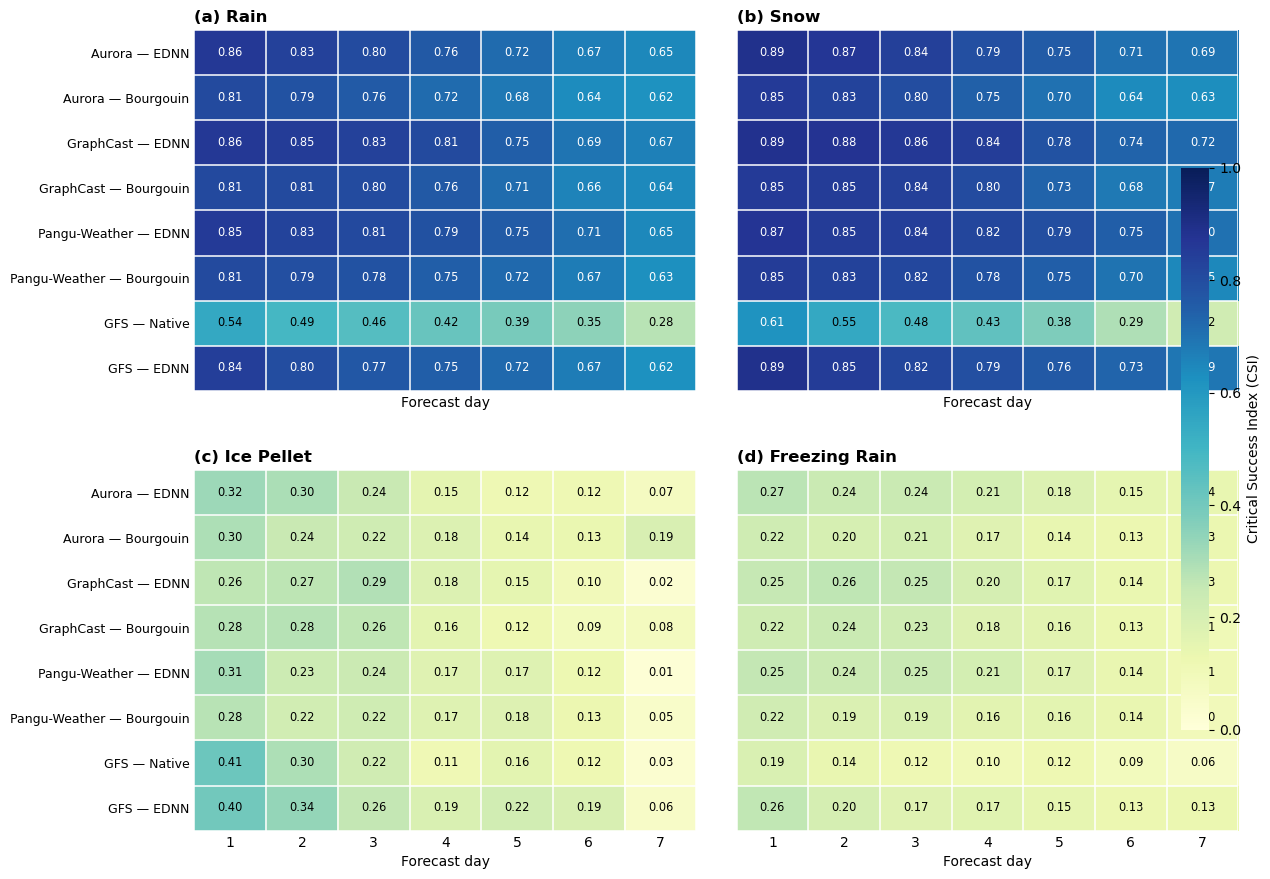

In [25]:
from matplotlib.ticker import MultipleLocator

# ============================================================
# Publication-quality CSI heatmap
# ============================================================

fig, axs = plt.subplots(2, 2, figsize=(14.5, 9.2), sharex=True, sharey=True)
axs = axs.ravel()
panel_labels = ["(a)", "(b)", "(c)", "(d)"]

# Keep one common physical scale across all classes/panels.
vmin, vmax = 0.0, 1.0

for ax, ptype, panel in zip(axs, CLASS_ORDER, panel_labels):
    z = (
        skill[skill.Class == ptype]
        .pivot(index="System", columns="Forecast_Day", values="CSI")
        .reindex(SYSTEM_ORDER)
        .reindex(columns=range(1, 8))
    )

    im = ax.imshow(
        z.values, cmap="YlGnBu", vmin=vmin, vmax=vmax,
        aspect="auto", interpolation="none"
    )

    ax.set_title(f"{panel} {ptype}", loc="left", fontsize=12, fontweight="bold")
    ax.set_xticks(np.arange(7), np.arange(1, 8))
    ax.set_yticks(np.arange(len(SYSTEM_ORDER)), SYSTEM_ORDER, fontsize=9)
    ax.set_xlabel("Forecast day", fontsize=10)

    # Thin white cell boundaries improve readability without dominating.
    ax.set_xticks(np.arange(-.5, 7, 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(SYSTEM_ORDER), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.tick_params(axis="both", length=0)

    # Values in each cell.
    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            val = z.iloc[i, j]
            if np.isfinite(val):
                ax.text(
                    j, i, f"{val:.2f}",
                    ha="center", va="center", fontsize=8.2,
                    color="white" if val >= 0.55 else "black"
                )

# Remove unnecessary spines.
for ax in axs:
    for spine in ax.spines.values():
        spine.set_visible(False)

# Shared colorbar.
cbar = fig.colorbar(
    im, ax=axs.tolist(), orientation="vertical",
    fraction=0.025, pad=0.025, ticks=np.arange(0, 1.01, .2)
)
cbar.set_label("Critical Success Index (CSI)", fontsize=10)
cbar.outline.set_visible(False)

fig.subplots_adjust(left=0.20, right=0.92, bottom=0.08, top=0.95, wspace=0.08, hspace=0.22)
plt.savefig(FIG/"multimodel_csi_heatmap.png", dpi=400, bbox_inches="tight")
plt.show()


### Verification tables: CSI, POD, FAR, and frequency bias

Rather than plotting additional heatmaps, retain the complementary metrics numerically. Two tables are produced:

1. **Complete verification table:** every forecast day, system, and precipitation class.
2. **Compact Day-1/Day-7 table:** useful for the manuscript or supplement when a smaller summary is needed.

Frequency bias (`FB`) is 1 for unbiased class frequency, >1 for overforecasting, and <1 for underforecasting.


In [26]:
# ============================================================
# Complete publication table: all forecast days
# ============================================================

verification_table = (
    skill[
        ["System", "Class", "Forecast_Day", "N", "Observed", "Forecast",
         "CSI", "POD", "FAR", "Frequency_Bias"]
    ]
    .rename(columns={
        "Forecast_Day": "Day",
        "Frequency_Bias": "FB"
    })
    .sort_values(["Class", "System", "Day"])
    .reset_index(drop=True)
)

for col in ["CSI", "POD", "FAR", "FB"]:
    verification_table[col] = verification_table[col].round(3)

display(verification_table)
verification_table.to_csv(OUT/"verification_metrics_all_days.csv", index=False)


# ============================================================
# Compact Day-1 / Day-7 table
# ============================================================

compact_table = (
    verification_table[verification_table.Day.isin([1, 7])]
    .pivot(
        index=["System", "Class"],
        columns="Day",
        values=["CSI", "POD", "FAR", "FB"]
    )
)

# Arrange columns by day, then metric.
compact_table = compact_table.swaplevel(0, 1, axis=1)
compact_table = compact_table.reindex(
    columns=pd.MultiIndex.from_product(
        [[1, 7], ["CSI", "POD", "FAR", "FB"]],
        names=["Forecast day", "Metric"]
    )
)

display(compact_table)
compact_table.to_csv(OUT/"verification_metrics_day1_day7.csv")


,System,Class,Day,N,Observed,Forecast,CSI,POD,FAR,FB
0,Aurora — Bourgouin,Freezing Rain,1,29536,816,1638,0.225,0.551,0.725,2.007
1,Aurora — Bourgouin,Freezing Rain,2,29546,816,1514,0.201,0.478,0.742,1.855
2,Aurora — Bourgouin,Freezing Rain,3,29560,818,1296,0.209,0.447,0.718,1.584
3,Aurora — Bourgouin,Freezing Rain,4,29532,818,1320,0.168,0.377,0.767,1.614
4,Aurora — Bourgouin,Freezing Rain,5,29514,816,1426,0.144,0.346,0.802,1.748
...,...,...,...,...,...,...,...,...,...,...
219,Pangu-Weather — EDNN,Snow,3,29560,15670,16722,0.840,0.944,0.116,1.067
220,Pangu-Weather — EDNN,Snow,4,29532,15634,16484,0.820,0.925,0.122,1.054
221,Pangu-Weather — EDNN,Snow,5,29514,15670,16444,0.794,0.907,0.135,1.049
222,Pangu-Weather — EDNN,Snow,6,29590,15750,16366,0.746,0.871,0.161,1.039


Forecast day                                 1                           7  \
Metric                                     CSI    POD    FAR     FB    CSI   
System                    Class                                              
Aurora — Bourgouin        Freezing Rain  0.225  0.551  0.725  2.007  0.130   
                          Ice Pellet     0.296  0.367  0.394  0.605  0.194   
                          Rain           0.806  0.912  0.126  1.043  0.618   
                          Snow           0.853  0.896  0.053  0.945  0.630   
Aurora — EDNN             Freezing Rain  0.271  0.441  0.587  1.069  0.144   
                          Ice Pellet     0.323  0.393  0.356  0.610  0.075   
                          Rain           0.861  0.910  0.059  0.968  0.646   
                          Snow           0.888  0.965  0.083  1.051  0.692   
GFS — EDNN                Freezing Rain  0.261  0.390  0.558  0.882  0.131   
                          Ice Pellet     0.400  0.562  0.420  0.970  0.058   
                          Rain           0.843  0.891  0.061  0.949  0.624   
                          Snow           0.887  0.962  0.081  1.047  0.690   
GFS — Native              Freezing Rain  0.189  0.331  0.695  1.086  0.060   
                          Ice Pellet     0.413  0.510  0.314  0.743  0.030   
                          Rain           0.543  0.569  0.078  0.617  0.277   
                          Snow           0.614  0.644  0.070  0.693  0.222   
GraphCast — Bourgouin     Freezing Rain  0.223  0.522  0.719  1.860  0.109   
                          Ice Pellet     0.278  0.329  0.359  0.513  0.081   
                          Rain           0.810  0.924  0.132  1.065  0.642   
                          Snow           0.853  0.895  0.052  0.944  0.672   
GraphCast — EDNN          Freezing Rain  0.253  0.431  0.622  1.140  0.129   
                          Ice Pellet     0.265  0.311  0.359  0.485  0.024   
                          Rain           0.860  0.915  0.066  0.979  0.668   
                          Snow           0.886  0.962  0.082  1.048  0.719   
Pangu-Weather — Bourgouin Freezing Rain  0.220  0.512  0.722  1.843  0.097   
                          Ice Pellet     0.276  0.331  0.372  0.526  0.050   
                          Rain           0.805  0.912  0.127  1.045  0.625   
                          Snow           0.849  0.899  0.062  0.958  0.647   
Pangu-Weather — EDNN      Freezing Rain  0.255  0.380  0.563  0.870  0.110   
                          Ice Pellet     0.308  0.378  0.377  0.607  0.012   
                          Rain           0.852  0.900  0.059  0.957  0.648   
                          Snow           0.875  0.966  0.097  1.070  0.701   

Forecast day                                                  
Metric                                     POD    FAR     FB  
System                    Class                               
Aurora — Bourgouin        Freezing Rain  0.294  0.812  1.560  
                          Ice Pellet     0.248  0.532  0.530  
                          Rain           0.869  0.319  1.277  
                          Snow           0.695  0.129  0.798  
Aurora — EDNN             Freezing Rain  0.252  0.749  1.005  
                          Ice Pellet     0.087  0.658  0.255  
                          Rain           0.833  0.258  1.123  
                          Snow           0.803  0.167  0.964  
GFS — EDNN                Freezing Rain  0.190  0.702  0.637  
                          Ice Pellet     0.069  0.741  0.265  
                          Rain           0.770  0.234  1.005  
                          Snow           0.846  0.210  1.071  
GFS — Native              Freezing Rain  0.077  0.786  0.358  
                          Ice Pellet     0.035  0.833  0.211  
                          Rain           0.298  0.204  0.374  
                          Snow           0.239  0.240  0.314  
GraphCast — Bourgouin     Freezing Rain  0.210  0.816  1.141  
         

## 9. Rain/snow reassignment of observed Ice Pellet and Freezing Rain

For each system, calculate

\[
P(\hat y \in \{\mathrm{Rain,Snow}\}\mid y_{\mathrm{mPING}}=\mathrm{Ice\ Pellet})
\]

and

\[
P(\hat y \in \{\mathrm{Rain,Snow}\}\mid y_{\mathrm{mPING}}=\mathrm{Freezing\ Rain}).
\]

This avoids the ambiguous term *mixed phase*.


In [27]:
collapse_rows = []

for system in SYSTEM_ORDER:
    s = common[common.System == system]
    for obs_name in FRZR_IP_CLASSES:
        x = s[s.obs_class == obs_name]
        for day in range(1,8):
            d = x[x.forecast_day == day]
            rs = d.pred_code.isin([CLASS_CODES["Rain"], CLASS_CODES["Snow"]])
            collapse_rows.append({
                "System": system,
                "Observed": obs_name,
                "Forecast_Day": day,
                "N": len(d),
                "RainSnow_Fraction": rs.mean(),
            })

collapse = pd.DataFrame(collapse_rows)
collapse.to_csv(OUT/"frzr_ip_reassignment_to_rain_snow.csv", index=False)
display(collapse.head())


,System,Observed,Forecast_Day,N,RainSnow_Fraction
0,Aurora — EDNN,Ice Pellet,1,1216,0.406250
1,Aurora — EDNN,Ice Pellet,2,1216,0.445724
2,Aurora — EDNN,Ice Pellet,3,1212,0.554455
3,Aurora — EDNN,Ice Pellet,4,1216,0.682566
4,Aurora — EDNN,Ice Pellet,5,1190,0.652101


### Rain/snow reassignment heatmaps


/glade/derecho/scratch/sakor/tmp/ipykernel_1195/1713030737.py:26: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0,0,.95,.95])


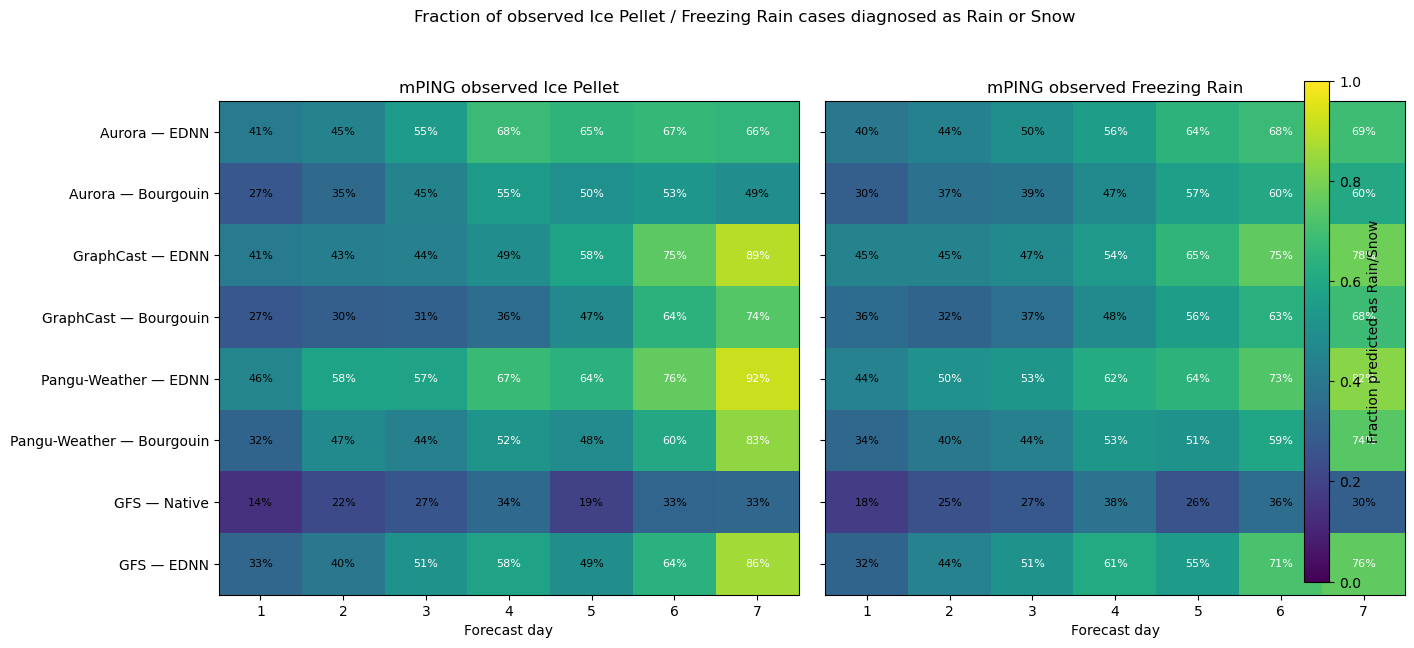

In [28]:
fig, axs = plt.subplots(1,2,figsize=(15,6.5), sharey=True)

for ax, obs_name in zip(axs, FRZR_IP_CLASSES):
    z = (
        collapse[collapse.Observed == obs_name]
        .pivot(index="System", columns="Forecast_Day", values="RainSnow_Fraction")
        .reindex(SYSTEM_ORDER)
        .reindex(columns=range(1,8))
    )

    im = ax.imshow(z.values, aspect="auto", vmin=0, vmax=1)
    ax.set_title(f"mPING observed {obs_name}")
    ax.set_xlabel("Forecast day")
    ax.set_xticks(range(7), range(1,8))
    ax.set_yticks(range(len(z.index)), z.index)

    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            val = z.iloc[i,j]
            if np.isfinite(val):
                ax.text(j,i,f"{100*val:.0f}%",ha="center",va="center",
                        color="white" if val > .5 else "black",fontsize=8)

fig.suptitle("Fraction of observed Ice Pellet / Freezing Rain cases diagnosed as Rain or Snow", y=.99)
fig.colorbar(im, ax=axs.tolist(), label="Fraction predicted as Rain/Snow", fraction=.035, pad=.03)
plt.tight_layout(rect=[0,0,.95,.95])
plt.savefig(FIG/"multimodel_frzr_ip_to_rain_snow_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. EDNN uncertainty dataset

Uncertainty is evaluated for the four EDNN applications only:

- Aurora
- GraphCast
- Pangu-Weather
- GFS

For each mPING-observed class:

\[
U_\mathrm{total}=U_\mathrm{aleatoric}+U_\mathrm{epistemic}.
\]

Unlike the eight-system skill comparison, the uncertainty comparison requires only the four EDNN datasets. We nevertheless restrict it to the same common `(obs_id, forecast_day)` keys used above so that uncertainty, reassignment and skill refer to the same observations.


In [29]:
unc_frames = []

for model in ["Aurora","GraphCast","Pangu-Weather","GFS"]:
    d = collocated[model].merge(common_keys, on=["obs_id","forecast_day"], how="inner").copy()
    d = d[d.spatial_match_valid & d.ML_ptype.isin(CLASS_NAMES)].copy()
    d["Model"] = model

    for ptype in CLASS_ORDER:
        d[f"{ptype}_epi"] = d[EPI_VARS[ptype]]
        d[f"{ptype}_ale"] = d[ALE_VARS[ptype]]
        d[f"{ptype}_total"] = d[EPI_VARS[ptype]] + d[ALE_VARS[ptype]]

    unc_frames.append(d)

unc = pd.concat(unc_frames, ignore_index=True)
print(unc.groupby("Model").size())


Model
Aurora           206786
GFS              206786
GraphCast        206786
Pangu-Weather    206786
dtype: int64


## 11. Total, epistemic and aleatoric uncertainty conditioned on mPING observation


In [30]:
unc_rows = []

for model in ["Aurora","GraphCast","Pangu-Weather","GFS"]:
    m = unc[unc.Model == model]
    for obs_name in FRZR_IP_CLASSES:
        x = m[m.obs_class == obs_name]
        for day in range(1,8):
            d = x[x.forecast_day == day]
            for component in ["total","epi","ale"]:
                q = d[f"{obs_name}_{component}"].dropna()
                unc_rows.append({
                    "Model": model, "Observed": obs_name, "Forecast_Day": day,
                    "Component": component, "N": len(q),
                    "Mean": q.mean(), "Median": q.median(),
                    "Q25": q.quantile(.25), "Q75": q.quantile(.75),
                })

unc_stats = pd.DataFrame(unc_rows)
unc_stats.to_csv(OUT/"ednn_uncertainty_by_observed_class.csv", index=False)
display(unc_stats.head())


,Model,Observed,Forecast_Day,Component,N,Mean,Median,Q25,Q75
0,Aurora,Ice Pellet,1,total,1216,0.145387,0.180536,0.043610,0.230975
1,Aurora,Ice Pellet,1,epi,1216,0.009224,0.011387,0.001856,0.014959
2,Aurora,Ice Pellet,1,ale,1216,0.136163,0.170039,0.041758,0.216064
3,Aurora,Ice Pellet,2,total,1216,0.137207,0.164278,0.031326,0.234994
4,Aurora,Ice Pellet,2,epi,1216,0.009098,0.010804,0.000982,0.015036


### Primary uncertainty figure: total predictive uncertainty with interquartile range

The line shows the median total predictive uncertainty. Shading shows the 25th–75th percentile interval for the same mPING-observed class. This is preferable to a median-only line because it shows both the lead-time tendency and the spread of uncertainty across individual observations.


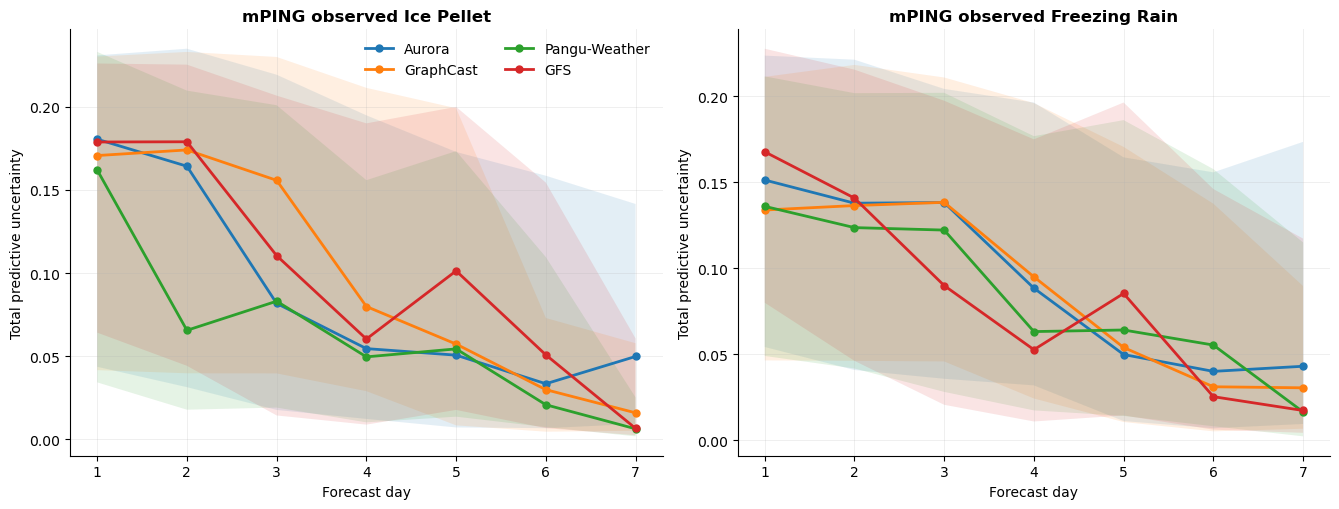

In [31]:
# ============================================================
# Total predictive uncertainty: median + IQR
# ============================================================

fig, axs = plt.subplots(1, 2, figsize=(13.5, 5.2), sharex=True)
models = ["Aurora", "GraphCast", "Pangu-Weather", "GFS"]

for ax, obs_name in zip(axs, FRZR_IP_CLASSES):
    for model in models:
        x = unc_stats[
            (unc_stats.Model == model) &
            (unc_stats.Observed == obs_name) &
            (unc_stats.Component == "total")
        ].sort_values("Forecast_Day")

        ax.plot(
            x.Forecast_Day, x.Median,
            marker="o", linewidth=2, markersize=5,
            label=model
        )

        ax.fill_between(
            x.Forecast_Day,
            x.Q25,
            x.Q75,
            alpha=0.12
        )

    ax.set_title(f"mPING observed {obs_name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Forecast day")
    ax.set_ylabel("Total predictive uncertainty")
    ax.set_xticks(range(1, 8))
    ax.grid(alpha=.20, linewidth=.7)
    ax.spines[["top", "right"]].set_visible(False)

axs[0].legend(frameon=False, ncol=2)
plt.tight_layout()
plt.savefig(FIG/"multimodel_total_uncertainty_iqr.png", dpi=400, bbox_inches="tight")
plt.show()


### Uncertainty-component diagnostic

This is primarily diagnostic/supplementary. It reveals whether contraction in total uncertainty is dominated by the aleatoric component, epistemic component, or both.


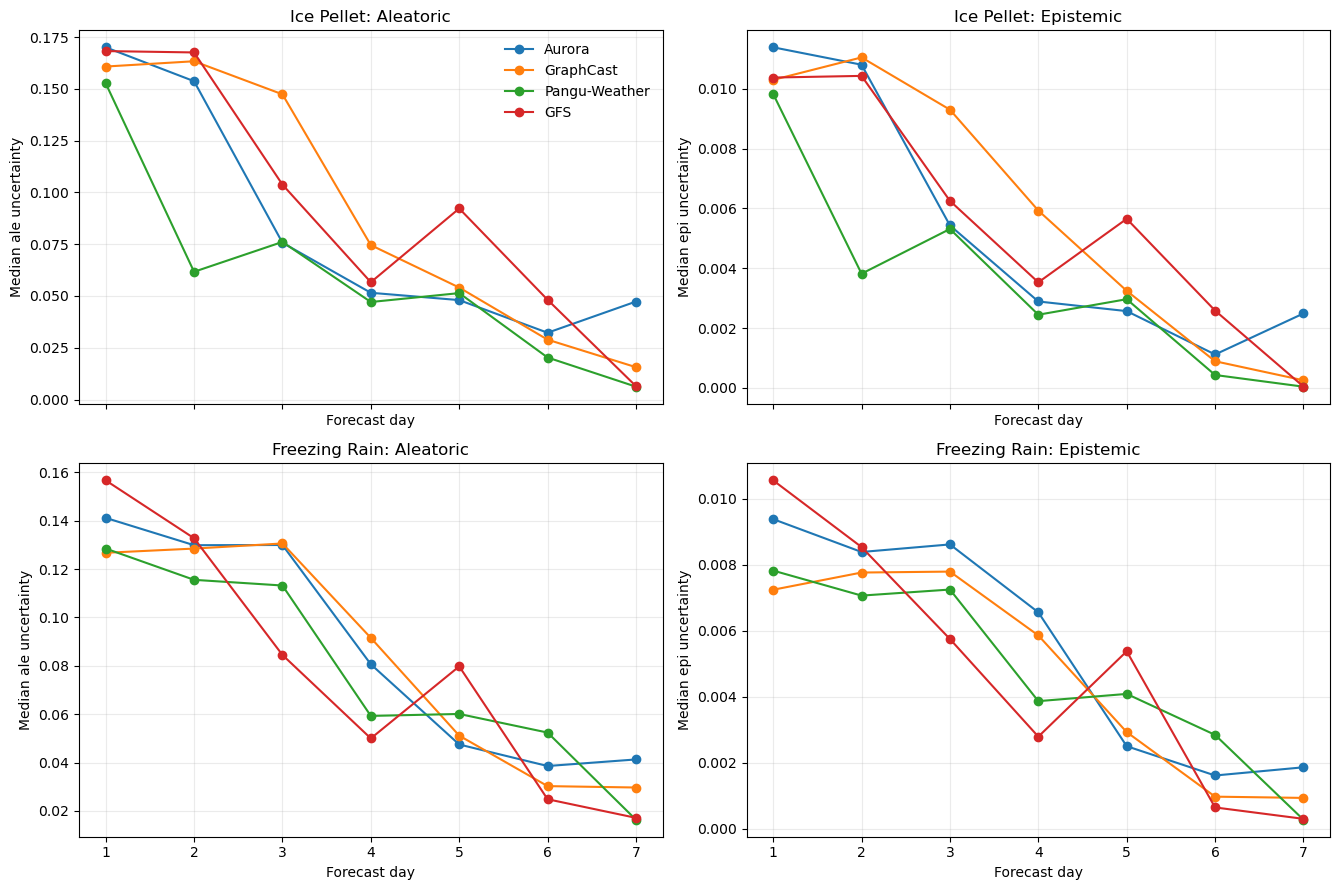

In [32]:
fig, axs = plt.subplots(2,2,figsize=(13.5,9), sharex=True)

for row, obs_name in enumerate(FRZR_IP_CLASSES):
    for col, component in enumerate(["ale","epi"]):
        ax = axs[row,col]
        for model in ["Aurora","GraphCast","Pangu-Weather","GFS"]:
            x = unc_stats[
                (unc_stats.Model == model) &
                (unc_stats.Observed == obs_name) &
                (unc_stats.Component == component)
            ].sort_values("Forecast_Day")
            ax.plot(x.Forecast_Day, x.Median, marker="o", label=model)

        title_component = "Aleatoric" if component == "ale" else "Epistemic"
        ax.set_title(f"{obs_name}: {title_component}")
        ax.set_xlabel("Forecast day")
        ax.set_ylabel(f"Median {component} uncertainty")
        ax.set_xticks(range(1,8))
        ax.grid(alpha=.25)

axs[0,0].legend(frameon=False)
plt.tight_layout()
plt.show()


## 12. EDNN reassignment versus total uncertainty

This connects the two phenomena quantitatively. Each point is one forecast day for one atmospheric forecast source.

The plot is descriptive: a relationship does not by itself prove the physical cause of the forecast-state change.


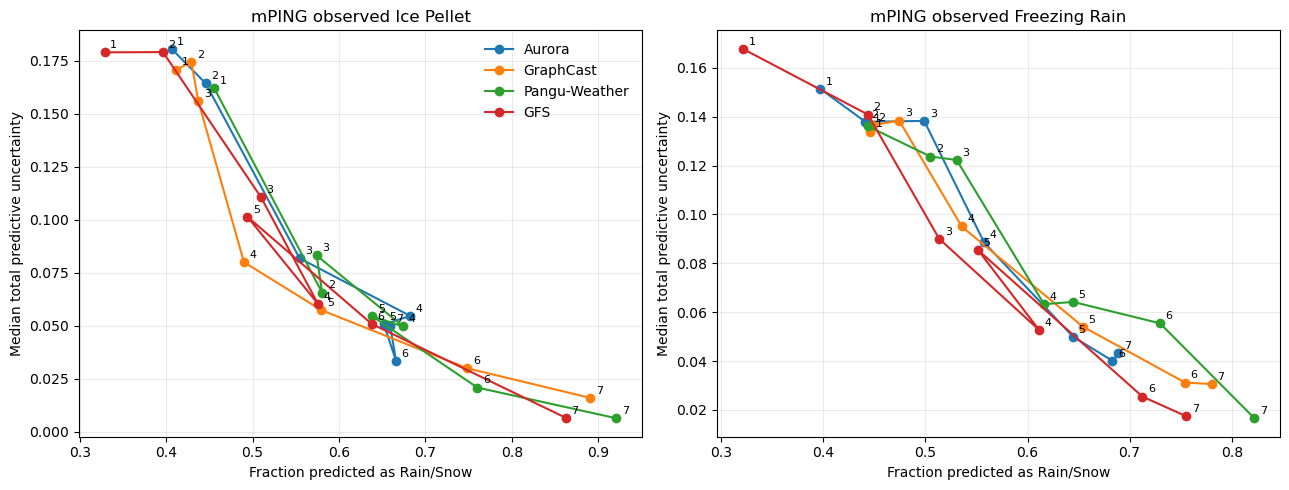

In [33]:
# EDNN-only collapse table
ednn_system = {
    "Aurora": "Aurora — EDNN",
    "GraphCast": "GraphCast — EDNN",
    "Pangu-Weather": "Pangu-Weather — EDNN",
    "GFS": "GFS — EDNN",
}

fig, axs = plt.subplots(1,2,figsize=(13,5))

for ax, obs_name in zip(axs, FRZR_IP_CLASSES):
    for model, system in ednn_system.items():
        c = collapse[(collapse.System == system) & (collapse.Observed == obs_name)][
            ["Forecast_Day","RainSnow_Fraction"]
        ]
        u = unc_stats[
            (unc_stats.Model == model) &
            (unc_stats.Observed == obs_name) &
            (unc_stats.Component == "total")
        ][["Forecast_Day","Median"]]

        z = c.merge(u, on="Forecast_Day").sort_values("Forecast_Day")
        ax.plot(z.RainSnow_Fraction, z.Median, marker="o", label=model)

        for r in z.itertuples():
            ax.annotate(str(r.Forecast_Day), (r.RainSnow_Fraction, r.Median),
                        xytext=(4,3), textcoords="offset points", fontsize=8)

    ax.set_title(f"mPING observed {obs_name}")
    ax.set_xlabel("Fraction predicted as Rain/Snow")
    ax.set_ylabel("Median total predictive uncertainty")
    ax.grid(alpha=.25)

axs[0].legend(frameon=False)
plt.tight_layout()
plt.show()


## 13. EDNN minus Bourgouin CSI within each AI-NWP

\[
\Delta CSI = CSI_{\mathrm{EDNN}} - CSI_{\mathrm{Bourgouin}}.
\]

The diverging scale is centered exactly at zero. **Blue denotes positive ΔCSI (EDNN higher CSI), red denotes negative ΔCSI (Bourgouin higher CSI), and white denotes no difference.** The same symmetric scale is used for all three AI-NWP panels.


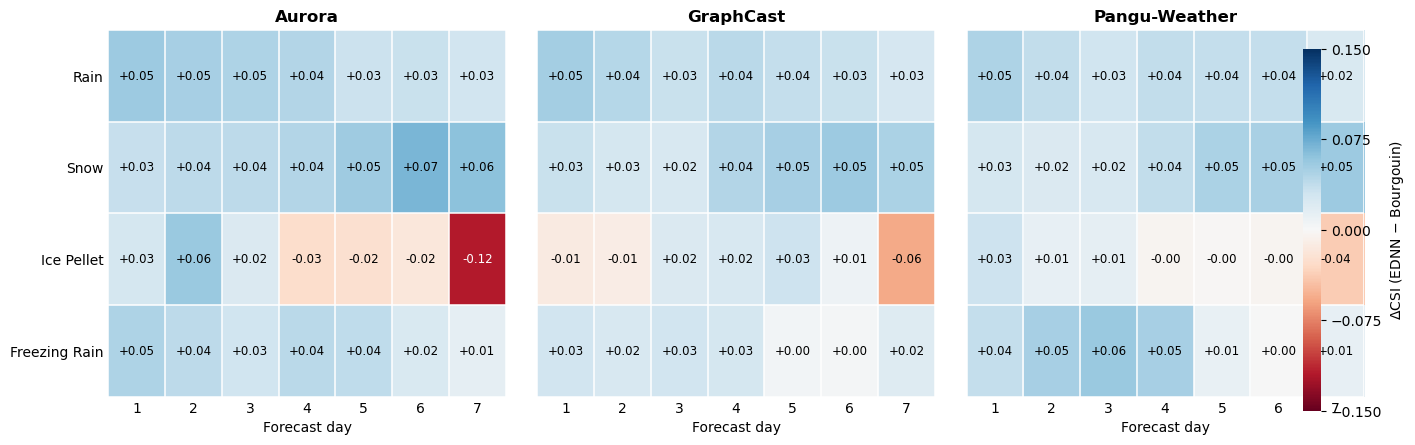

Shared ΔCSI color scale: -0.15 to 0.15


In [34]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import MaxNLocator

delta_rows = []

for model in ["Aurora", "GraphCast", "Pangu-Weather"]:
    for ptype in CLASS_ORDER:
        e = skill[
            (skill.System == f"{model} — EDNN") &
            (skill.Class == ptype)
        ][["Forecast_Day", "CSI"]].rename(columns={"CSI": "CSI_EDNN"})

        b = skill[
            (skill.System == f"{model} — Bourgouin") &
            (skill.Class == ptype)
        ][["Forecast_Day", "CSI"]].rename(columns={"CSI": "CSI_Bourgouin"})

        z = e.merge(b, on="Forecast_Day")
        z["Delta_CSI"] = z.CSI_EDNN - z.CSI_Bourgouin
        z["Model"] = model
        z["Class"] = ptype
        delta_rows.append(z)

delta = pd.concat(delta_rows, ignore_index=True)
delta.to_csv(OUT/"ednn_minus_bourgouin_csi.csv", index=False)

# Symmetric scale around zero, rounded upward to a clean 0.05 interval.
raw_lim = np.nanmax(np.abs(delta.Delta_CSI))
lim = max(0.05, np.ceil(raw_lim / 0.05) * 0.05)
norm = TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)

fig, axs = plt.subplots(1, 3, figsize=(15.5, 4.7), sharey=True)

for ax, model in zip(axs, ["Aurora", "GraphCast", "Pangu-Weather"]):
    z = (
        delta[delta.Model == model]
        .pivot(index="Class", columns="Forecast_Day", values="Delta_CSI")
        .reindex(CLASS_ORDER)
        .reindex(columns=range(1, 8))
    )

    # RdBu: negative values red, zero white, positive values blue.
    im = ax.imshow(
        z.values, cmap="RdBu", norm=norm,
        aspect="auto", interpolation="none"
    )

    ax.set_title(model, fontsize=12, fontweight="bold")
    ax.set_xticks(np.arange(7), np.arange(1, 8))
    ax.set_yticks(np.arange(len(CLASS_ORDER)), CLASS_ORDER)
    ax.set_xlabel("Forecast day")
    ax.tick_params(length=0)

    ax.set_xticks(np.arange(-.5, 7, 1), minor=True)
    ax.set_yticks(np.arange(-.5, len(CLASS_ORDER), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.1)
    ax.tick_params(which="minor", bottom=False, left=False)

    for i in range(z.shape[0]):
        for j in range(z.shape[1]):
            val = z.iloc[i, j]
            if np.isfinite(val):
                # Dark text close to zero; white text near either extreme.
                txt_color = "white" if abs(val) > 0.60*lim else "black"
                ax.text(j, i, f"{val:+.2f}", ha="center", va="center",
                        fontsize=8.5, color=txt_color)

    for spine in ax.spines.values():
        spine.set_visible(False)

ticks = np.linspace(-lim, lim, 5)
cbar = fig.colorbar(im, ax=axs.tolist(), fraction=.025, pad=.025, ticks=ticks)
cbar.set_label(r"$\Delta$CSI (EDNN $-$ Bourgouin)")
cbar.outline.set_visible(False)

fig.subplots_adjust(left=.11, right=.92, bottom=.14, top=.92, wspace=.08)
plt.savefig(FIG/"ednn_minus_bourgouin_csi_heatmap.png", dpi=400, bbox_inches="tight")
plt.show()

print(f"Shared ΔCSI color scale: {-lim:.2f} to {lim:.2f}")


## 14. Day-1 to Day-7 summary tables


In [35]:
# Skill changes
skill_change = (
    skill[skill.Forecast_Day.isin([1,7])]
    .pivot_table(index=["System","Class"], columns="Forecast_Day", values=["CSI","POD","FAR","Frequency_Bias"])
)
skill_change.columns = [f"{m}_D{d}" for m,d in skill_change.columns]
skill_change = skill_change.reset_index()

for m in ["CSI","POD","FAR","Frequency_Bias"]:
    skill_change[f"{m}_change"] = skill_change[f"{m}_D7"] - skill_change[f"{m}_D1"]

# Reassignment changes
collapse_change = (
    collapse[collapse.Forecast_Day.isin([1,7])]
    .pivot(index=["System","Observed"], columns="Forecast_Day", values="RainSnow_Fraction")
    .rename(columns={1:"D1",7:"D7"}).reset_index()
)
collapse_change["Change"] = collapse_change.D7 - collapse_change.D1

# Total uncertainty changes
total_change = (
    unc_stats[
        (unc_stats.Component == "total") &
        unc_stats.Forecast_Day.isin([1,7])
    ]
    .pivot(index=["Model","Observed"], columns="Forecast_Day", values="Median")
    .rename(columns={1:"D1",7:"D7"}).reset_index()
)
total_change["Absolute_change"] = total_change.D7 - total_change.D1
total_change["Percent_change"] = (total_change.D7/total_change.D1 - 1)*100

display(skill_change.round(3))
display(collapse_change.round(3))
display(total_change.round(3))

skill_change.to_csv(OUT/"day1_day7_skill_changes.csv", index=False)
collapse_change.to_csv(OUT/"day1_day7_rainsnow_reassignment_changes.csv", index=False)
total_change.to_csv(OUT/"day1_day7_total_uncertainty_changes.csv", index=False)


,System,Class,CSI_D1,CSI_D7,FAR_D1,FAR_D7,Frequency_Bias_D1,Frequency_Bias_D7,POD_D1,POD_D7,CSI_change,POD_change,FAR_change,Frequency_Bias_change
0,Aurora — Bourgouin,Freezing Rain,0.225,0.130,0.725,0.812,2.007,1.560,0.551,0.294,-0.095,-0.258,0.086,-0.447
1,Aurora — Bourgouin,Ice Pellet,0.296,0.194,0.394,0.532,0.605,0.530,0.367,0.248,-0.102,-0.118,0.138,-0.075
2,Aurora — Bourgouin,Rain,0.806,0.618,0.126,0.319,1.043,1.277,0.912,0.869,-0.188,-0.043,0.193,0.233
3,Aurora — Bourgouin,Snow,0.853,0.630,0.053,0.129,0.945,0.798,0.896,0.695,-0.224,-0.201,0.077,-0.147
4,Aurora — EDNN,Freezing Rain,0.271,0.144,0.587,0.749,1.069,1.005,0.441,0.252,-0.127,-0.189,0.162,-0.064
5,Aurora — EDNN,Ice Pellet,0.323,0.075,0.356,0.658,0.610,0.255,0.393,0.087,-0.248,-0.306,0.302,-0.355
6,Aurora — EDNN,Rain,0.861,0.646,0.059,0.258,0.968,1.123,0.910,0.833,-0.214,-0.077,0.198,0.155
7,Aurora — EDNN,Snow,0.888,0.692,0.083,0.167,1.051,0.964,0.965,0.803,-0.196,-0.162,0.085,-0.087
8,GFS — EDNN,Freezing Rain,0.261,0.131,0.558,0.702,0.882,0.637,0.390,0.190,-0.130,-0.200,0.143,-0.245
9,GFS — EDNN,Ice Pellet,0.400,0.058,0.420,0.741,0.970,0.265,0.562,0.069,-0.342,-0.494,0.320,-0.705


Forecast_Day,System,Observed,D1,D7,Change
0,Aurora — Bourgouin,Freezing Rain,0.304,0.602,0.299
1,Aurora — Bourgouin,Ice Pellet,0.273,0.492,0.219
2,Aurora — EDNN,Freezing Rain,0.397,0.689,0.292
3,Aurora — EDNN,Ice Pellet,0.406,0.659,0.253
4,GFS — EDNN,Freezing Rain,0.321,0.756,0.434
5,GFS — EDNN,Ice Pellet,0.329,0.862,0.533
6,GFS — Native,Freezing Rain,0.181,0.304,0.122
7,GFS — Native,Ice Pellet,0.141,0.329,0.187
8,GraphCast — Bourgouin,Freezing Rain,0.355,0.684,0.329
9,GraphCast — Bourgouin,Ice Pellet,0.273,0.737,0.464


Forecast_Day,Model,Observed,D1,D7,Absolute_change,Percent_change
0,Aurora,Freezing Rain,0.151,0.043,-0.108,-71.508003
1,Aurora,Ice Pellet,0.181,0.050,-0.131,-72.413002
2,GFS,Freezing Rain,0.168,0.017,-0.150,-89.619003
3,GFS,Ice Pellet,0.179,0.007,-0.172,-96.356003
4,GraphCast,Freezing Rain,0.134,0.031,-0.103,-77.155998
5,GraphCast,Ice Pellet,0.171,0.016,-0.155,-90.694000
6,Pangu-Weather,Freezing Rain,0.136,0.017,-0.119,-87.797997
7,Pangu-Weather,Ice Pellet,0.162,0.006,-0.156,-96.133003


## 15. Interpretation checklist

Before drawing conclusions, check these jointly:

- Does CSI decline with lead time for Ice Pellet and Freezing Rain?
- Does the fraction of those mPING-observed cases diagnosed as Rain/Snow increase?
- Is the increase present in **both EDNN and Bourgouin** for the same AI-NWP?
- Does native GFS show a similar or different lead-time behavior?
- Does total EDNN predictive uncertainty decrease for those same observed cases?
- Do both aleatoric and epistemic components contract, or is one dominant?
- Are conclusions robust on the identical common-valid sample?

If EDNN and Bourgouin show similar reassignment for the same atmospheric forecast, that is consistent with degradation/change in the forecast thermodynamic state contributing to the behavior. It does **not by itself prove** the meteorological mechanism; demonstrating that would require analysis of the forecast temperature/moisture profiles.


,Model,obs_class,forecast_day,Outcome,N
0,Aurora,Freezing Rain,1,Correct,360
1,Aurora,Freezing Rain,1,Predicted Ice Pellet,132
2,Aurora,Freezing Rain,1,Predicted Rain/Snow,324
3,Aurora,Freezing Rain,2,Correct,300
4,Aurora,Freezing Rain,2,Predicted Ice Pellet,156
...,...,...,...,...,...
163,Pangu-Weather,Ice Pellet,6,Predicted Freezing Rain,118
164,Pangu-Weather,Ice Pellet,6,Predicted Rain/Snow,920
165,Pangu-Weather,Ice Pellet,7,Correct,16
166,Pangu-Weather,Ice Pellet,7,Predicted Freezing Rain,78


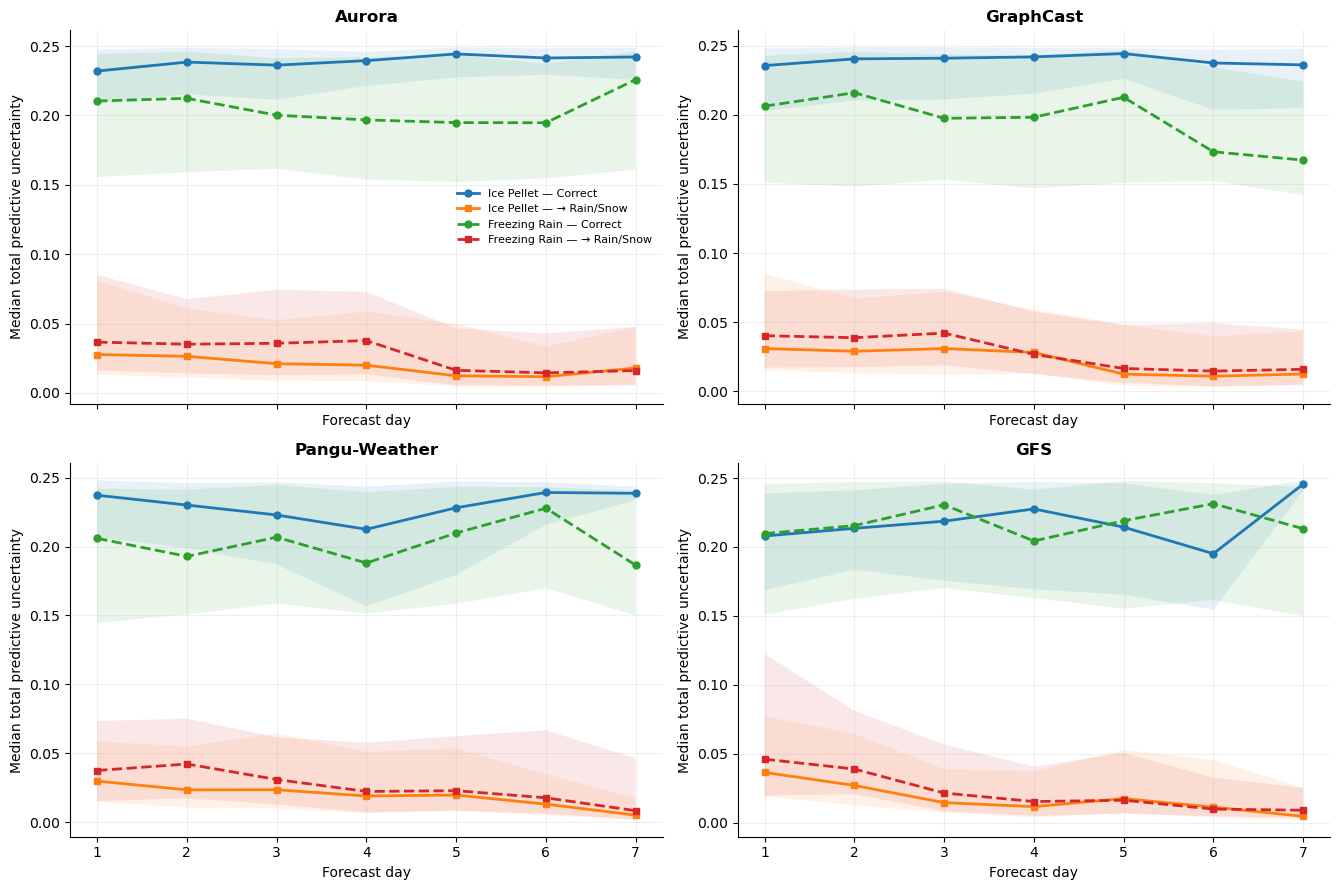

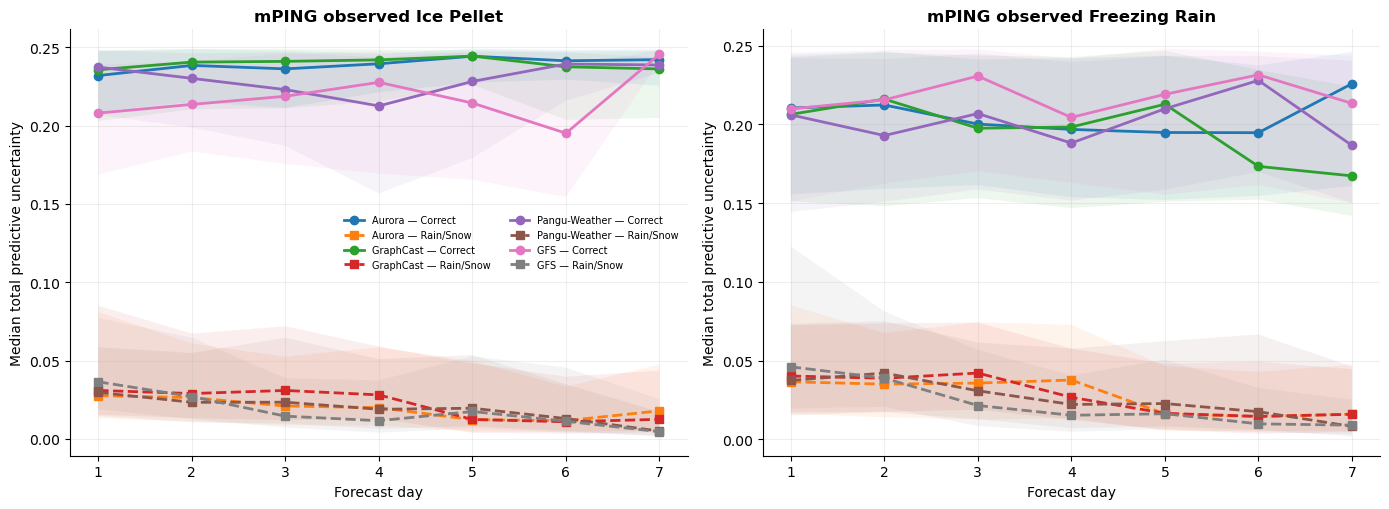

forecast_day,Model,obs_class,Outcome,Day1,Day7,Absolute_change,Percent_change
0,Aurora,Freezing Rain,Correct,0.2104,0.2258,0.0154,7.320100
1,Aurora,Freezing Rain,Predicted Rain/Snow,0.0366,0.0161,-0.0205,-56.061600
2,Aurora,Ice Pellet,Correct,0.2320,0.2421,0.0102,4.382200
3,Aurora,Ice Pellet,Predicted Rain/Snow,0.0276,0.0179,-0.0097,-35.030201
4,GFS,Freezing Rain,Correct,0.2098,0.2133,0.0035,1.681900
5,GFS,Freezing Rain,Predicted Rain/Snow,0.0461,0.0090,-0.0370,-80.376999
6,GFS,Ice Pellet,Correct,0.2080,0.2456,0.0376,18.073601
7,GFS,Ice Pellet,Predicted Rain/Snow,0.0365,0.0046,-0.0318,-87.340897
8,GraphCast,Freezing Rain,Correct,0.2063,0.1673,-0.0390,-18.924601
9,GraphCast,Freezing Rain,Predicted Rain/Snow,0.0402,0.0159,-0.0243,-60.383598


In [36]:
# ============================================================
# EDNN TOTAL UNCERTAINTY BY FORECAST OUTCOME
# ============================================================
#
# For mPING-observed Ice Pellet and Freezing Rain, separate EDNN
# forecasts into:
#   1. Correct
#   2. Misclassified as Rain/Snow
#   3. Misclassified as the other freezing category
#
# Total uncertainty is defined as:
#   aleatoric + epistemic
#
# The main figure compares:
#   Correct vs Predicted Rain/Snow
#
# Assumes these already exist:
#   collocated
#   common_keys
#   CLASS_CODES
#   FRZR_IP_CLASSES
#   ALE_VARS
#   EPI_VARS
# ============================================================


EDNN_MODELS = [
    "Aurora",
    "GraphCast",
    "Pangu-Weather",
    "GFS",
]


# ============================================================
# CLASSIFY FORECAST OUTCOME
# ============================================================

def classify_outcome(pred_code, obs_name):

    obs_code = CLASS_CODES[obs_name]

    # Correct forecast
    if pred_code == obs_code:
        return "Correct"

    # Misclassified into dominant classes
    if pred_code in [
        CLASS_CODES["Rain"],
        CLASS_CODES["Snow"]
    ]:
        return "Predicted Rain/Snow"

    # Confusion between Ice Pellet and Freezing Rain
    if (
        obs_name == "Ice Pellet"
        and pred_code == CLASS_CODES["Freezing Rain"]
    ):
        return "Predicted Freezing Rain"

    if (
        obs_name == "Freezing Rain"
        and pred_code == CLASS_CODES["Ice Pellet"]
    ):
        return "Predicted Ice Pellet"

    return "Other"


# ============================================================
# BUILD OUTCOME-LEVEL UNCERTAINTY DATASET
# ============================================================

outcome_frames = []

for model in EDNN_MODELS:

    d = (
        collocated[model]
        .merge(
            common_keys,
            on=["obs_id", "forecast_day"],
            how="inner"
        )
        .copy()
    )

    # Valid EDNN prediction + valid spatial match
    d = d[
        d["spatial_match_valid"]
        & d["ML_ptype"].isin([0, 1, 2, 3])
    ].copy()

    d["Model"] = model

    for obs_name in FRZR_IP_CLASSES:

        x = d[
            d["obs_class"] == obs_name
        ].copy()

        # Forecast outcome
        x["Outcome"] = [
            classify_outcome(pred, obs_name)
            for pred in x["ML_ptype"]
        ]

        # Total uncertainty corresponding to the OBSERVED class
        x["total_uncertainty"] = (
            x[ALE_VARS[obs_name]]
            + x[EPI_VARS[obs_name]]
        )

        outcome_frames.append(
            x[
                [
                    "Model",
                    "obs_id",
                    "forecast_day",
                    "obs_class",
                    "ML_ptype",
                    "Outcome",
                    "total_uncertainty",
                ]
            ]
        )


unc_outcome = pd.concat(
    outcome_frames,
    ignore_index=True
)


# ============================================================
# SUMMARIZE MEDIAN + IQR
# ============================================================

outcome_stats = (
    unc_outcome
    .groupby(
        [
            "Model",
            "obs_class",
            "forecast_day",
            "Outcome",
        ]
    )["total_uncertainty"]
    .agg(
        N="count",
        Mean="mean",
        Median="median",
        Q25=lambda x: x.quantile(0.25),
        Q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)


# ============================================================
# DISPLAY SAMPLE COUNTS
# ============================================================

counts = (
    unc_outcome
    .groupby(
        [
            "Model",
            "obs_class",
            "forecast_day",
            "Outcome",
        ]
    )
    .size()
    .rename("N")
    .reset_index()
)

display(counts)


# ============================================================
# MAIN FIGURE
# CORRECT vs MISCLASSIFIED AS RAIN/SNOW
# ============================================================

plot_stats = outcome_stats[
    outcome_stats["Outcome"].isin(
        [
            "Correct",
            "Predicted Rain/Snow",
        ]
    )
].copy()


fig, axs = plt.subplots(
    2,
    2,
    figsize=(13.5, 9),
    sharex=True
)

for ax, model in zip(
    axs.ravel(),
    EDNN_MODELS
):

    for obs_name, linestyle in [
        ("Ice Pellet", "-"),
        ("Freezing Rain", "--"),
    ]:

        for outcome, marker in [
            ("Correct", "o"),
            ("Predicted Rain/Snow", "s"),
        ]:

            x = plot_stats[
                (plot_stats["Model"] == model)
                & (plot_stats["obs_class"] == obs_name)
                & (plot_stats["Outcome"] == outcome)
            ].sort_values("forecast_day")

            label = (
                f"{obs_name} — "
                f"{'Correct' if outcome == 'Correct' else '→ Rain/Snow'}"
            )

            ax.plot(
                x["forecast_day"],
                x["Median"],
                marker=marker,
                linestyle=linestyle,
                linewidth=2,
                markersize=5,
                label=label,
            )

            ax.fill_between(
                x["forecast_day"],
                x["Q25"],
                x["Q75"],
                alpha=0.10,
            )

    ax.set_title(
        model,
        fontweight="bold"
    )

    ax.set_xlabel(
        "Forecast day"
    )

    ax.set_ylabel(
        "Median total predictive uncertainty"
    )

    ax.set_xticks(
        range(1, 8)
    )

    ax.grid(
        alpha=0.20
    )

    ax.spines[
        ["top", "right"]
    ].set_visible(False)


axs[0, 0].legend(
    fontsize=8,
    frameon=False
)

plt.tight_layout()

plt.savefig(
    FIG / "ednn_uncertainty_correct_vs_rainsnow.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# CLEANER TWO-PANEL FIGURE
# ONE PANEL PER OBSERVED CLASS
# ============================================================

fig, axs = plt.subplots(
    1,
    2,
    figsize=(14, 5.2),
    sharex=True
)

for ax, obs_name in zip(
    axs,
    FRZR_IP_CLASSES
):

    for model in EDNN_MODELS:

        # --------------------------------------------
        # Correct forecasts
        # --------------------------------------------

        x_correct = plot_stats[
            (plot_stats["Model"] == model)
            & (plot_stats["obs_class"] == obs_name)
            & (plot_stats["Outcome"] == "Correct")
        ].sort_values("forecast_day")

        ax.plot(
            x_correct["forecast_day"],
            x_correct["Median"],
            marker="o",
            linewidth=2,
            label=f"{model} — Correct",
        )

        ax.fill_between(
            x_correct["forecast_day"],
            x_correct["Q25"],
            x_correct["Q75"],
            alpha=0.08,
        )


        # --------------------------------------------
        # Misclassified as Rain/Snow
        # --------------------------------------------

        x_rs = plot_stats[
            (plot_stats["Model"] == model)
            & (plot_stats["obs_class"] == obs_name)
            & (
                plot_stats["Outcome"]
                == "Predicted Rain/Snow"
            )
        ].sort_values("forecast_day")

        ax.plot(
            x_rs["forecast_day"],
            x_rs["Median"],
            marker="s",
            linestyle="--",
            linewidth=2,
            label=f"{model} — Rain/Snow",
        )

        ax.fill_between(
            x_rs["forecast_day"],
            x_rs["Q25"],
            x_rs["Q75"],
            alpha=0.08,
        )


    ax.set_title(
        f"mPING observed {obs_name}",
        fontweight="bold"
    )

    ax.set_xlabel(
        "Forecast day"
    )

    ax.set_ylabel(
        "Median total predictive uncertainty"
    )

    ax.set_xticks(
        range(1, 8)
    )

    ax.grid(
        alpha=0.20
    )

    ax.spines[
        ["top", "right"]
    ].set_visible(False)


axs[0].legend(
    fontsize=7,
    frameon=False,
    ncol=2
)

plt.tight_layout()

plt.savefig(
    FIG / "ednn_uncertainty_by_correctness.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# NUMERICAL DAY-1 TO DAY-7 SUMMARY
# ============================================================

summary = (
    plot_stats[
        plot_stats["forecast_day"].isin([1, 7])
    ]
    .pivot_table(
        index=[
            "Model",
            "obs_class",
            "Outcome",
        ],
        columns="forecast_day",
        values="Median"
    )
    .rename(
        columns={
            1: "Day1",
            7: "Day7",
        }
    )
    .reset_index()
)

summary["Absolute_change"] = (
    summary["Day7"]
    - summary["Day1"]
)

summary["Percent_change"] = (
    summary["Day7"]
    / summary["Day1"]
    - 1
) * 100


display(
    summary.round(4)
)

# summary.to_csv(
#     OUT / "ednn_uncertainty_correct_vs_rainsnow_day1_day7.csv",
#     index=False
# )


# # ============================================================
# # OPTIONAL: SAVE FULL OUTCOME TABLE
# # ============================================================

# outcome_stats.to_csv(
#     OUT / "ednn_uncertainty_by_forecast_outcome.csv",
#     index=False
# )